# B3: Histogram dan Perbaikan Citra
SIMUTEH | SEED = 1013 | NIM 2330511013

In [1]:
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak, statistik
D = "../data/sintetis"
def muat(nama):
    img = baca(f"{D}/citra/{nama}")
    md = cv2.imread(f"{D}/mask_daun/{nama}", 0)
    mb = cv2.imread(f"{D}/mask_bercak/{nama}", 0)
    return img, md, mb

## Langkah 3.2 Diagnosis mutu (Kode 3.1)

teh_041.png {'rerata': 182.8, 'simpangan_baku': 39.2, 'min': 73, 'maks': 226, 'persen_gelap': 0.0, 'persen_terang': 20.6}
teh_042.png {'rerata': 119.7, 'simpangan_baku': 40.5, 'min': 7, 'maks': 184, 'persen_gelap': 13.9, 'persen_terang': 0.0}
teh_043.png {'rerata': 213.5, 'simpangan_baku': 29.1, 'min': 131, 'maks': 254, 'persen_gelap': 0.0, 'persen_terang': 74.4}
teh_044.png {'rerata': 152.6, 'simpangan_baku': 14.3, 'min': 105, 'maks': 185, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 122.2, 'simpangan_baku': 56.7, 'min': 12, 'maks': 249, 'persen_gelap': 4.7, 'persen_terang': 10.3}


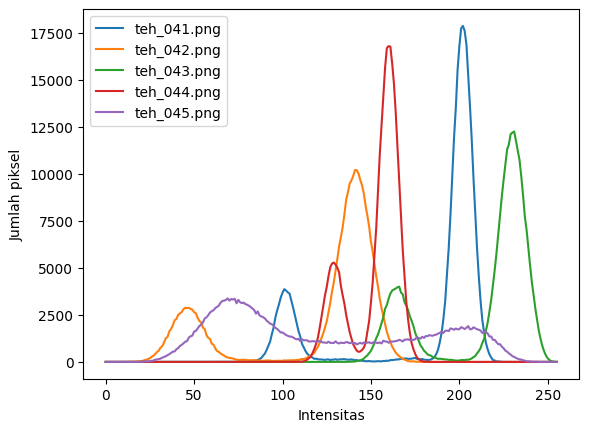

In [2]:
for nama in ["teh_041.png", "teh_042.png", "teh_043.png",
             "teh_044.png", "teh_045.png"]:
    gray = cv2.cvtColor(baca(f"{D}/citra/{nama}"), cv2.COLOR_BGR2GRAY)
    print(nama, statistik(gray))
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend()
plt.savefig("../hasil/b3_histogram_5kondisi.png")

In [3]:
# kelas ringan teh_021 sampai teh_025 (Tabel 9, baris terakhir)
baris = []
for n in range(21, 26):
    nama = f"teh_{n:03d}.png"
    gray = cv2.cvtColor(baca(f"{D}/citra/{nama}"), cv2.COLOR_BGR2GRAY)
    s = statistik(gray); s["citra"] = nama; baris.append(s)
t9r = pd.DataFrame(baris).set_index("citra"); print(t9r)
print("rata-rata:", t9r.mean().round(1).to_dict())
t9 = pd.DataFrame([{**statistik(cv2.cvtColor(baca(f"{D}/citra/teh_0{n}.png"), cv2.COLOR_BGR2GRAY)), "citra": f"teh_0{n}"} for n in range(41, 46)]).set_index("citra")
pd.concat([t9, t9r]).to_csv("../hasil/b3_tabel9.csv")

             rerata  simpangan_baku  min  maks  persen_gelap  persen_terang
citra                                                                      
teh_021.png   163.2            36.5   73   212           0.0            0.1
teh_022.png   111.8            45.0    4   179          23.5            0.0
teh_023.png   210.2            22.2  149   247           0.0           74.9
teh_024.png   154.2            16.5   92   201           0.0            0.0
teh_025.png   121.9            52.5   28   241           0.8            9.4
rata-rata: {'rerata': 152.3, 'simpangan_baku': 34.5, 'min': 69.2, 'maks': 216.0, 'persen_gelap': 4.9, 'persen_terang': 16.9}


## Langkah 3.3 Perbaikan citra kondisi bayangan (Kode 3.2)

In [4]:
nama = "teh_045.png"                 # kondisi bayangan
img, md, mb = muat(nama)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))      # abaikan 2% piksel ekstrem
hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255,
                      0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(clipLimit=2.0,
                             tileGridSize=(8, 8)).apply(gray),
}
for nm, c_ in hasil.items():
    print(f"{nm:10s} KB={kontras_bercak(c_, md, mb):.2f} "
          f"sigma={c_.std():.1f}")
print("rmin, rmax (persentil 2, 98):", rmin, rmax, "| min-maks asli:", gray.min(), gray.max())

asli       KB=1.32 sigma=56.7
negatif    KB=1.32 sigma=56.7
cerah+50   KB=1.32 sigma=54.8
kontras    KB=1.32 sigma=79.8
regang     KB=1.36 sigma=79.8
gamma0.5   KB=1.17 sigma=41.3
gamma1.8   KB=1.57 sigma=60.3
ekualisasi KB=1.15 sigma=73.4
CLAHE      KB=1.86 sigma=46.9
rmin, rmax (persentil 2, 98): 42.0 222.0 | min-maks asli: 12 249


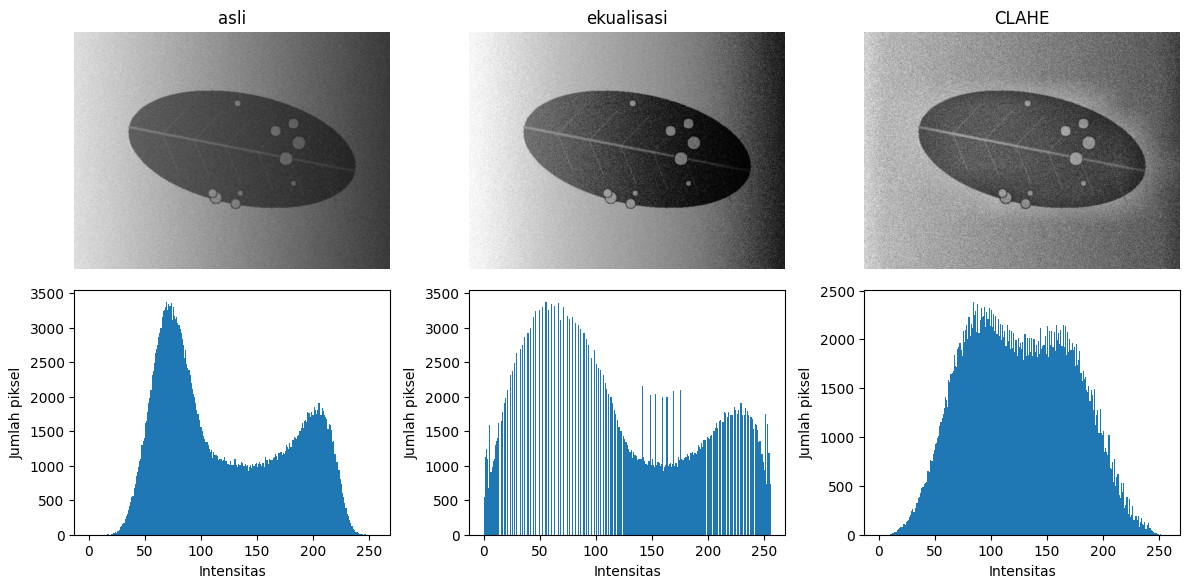

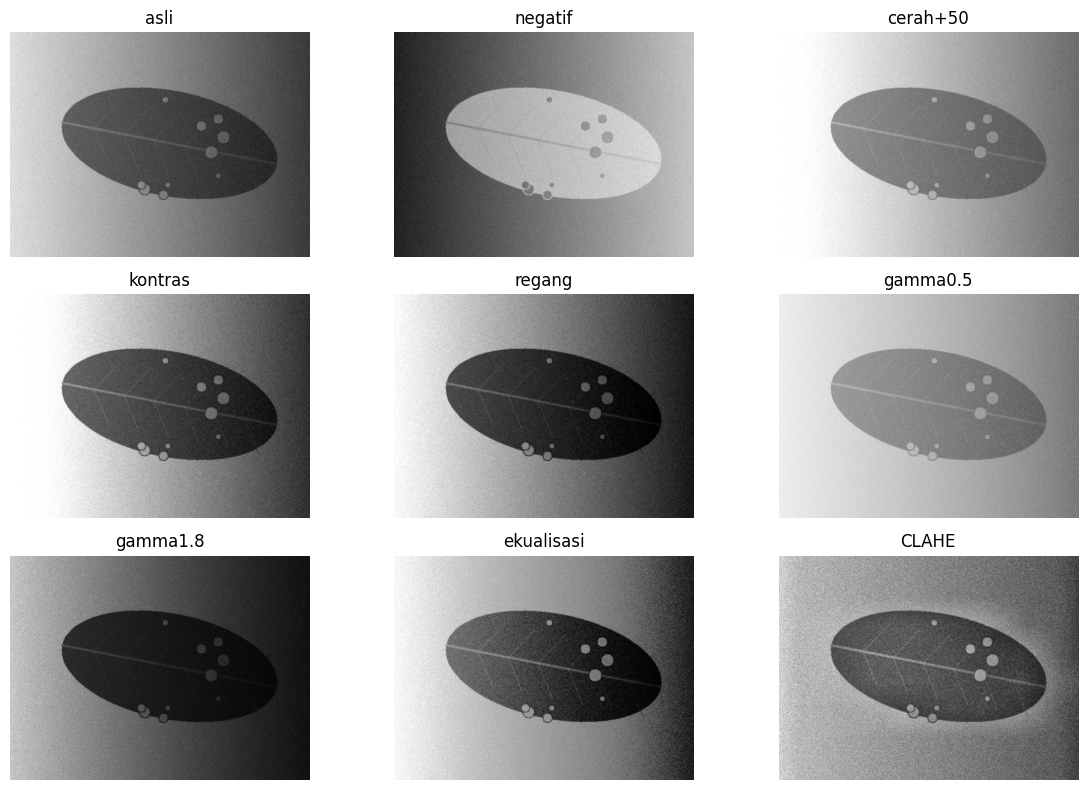

In [5]:
# Gambar 4: asli, ekualisasi global, CLAHE beserta histogramnya
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for i, nm in enumerate(["asli", "ekualisasi", "CLAHE"]):
    ax[0, i].imshow(hasil[nm], cmap="gray", vmin=0, vmax=255); ax[0, i].set_title(nm); ax[0, i].axis("off")
    ax[1, i].hist(hasil[nm].ravel(), bins=256, range=(0, 256)); ax[1, i].set_xlabel("Intensitas"); ax[1, i].set_ylabel("Jumlah piksel")
plt.tight_layout(); plt.savefig("../hasil/b3_gambar4.png")
tampil(list(hasil.values()), list(hasil.keys()), baris=3, ukuran=(12, 8))
plt.savefig("../hasil/b3_panel_metode.png")
pd.DataFrame([[k, round(kontras_bercak(v, md, mb), 2), round(float(v.std()), 1)] for k, v in hasil.items()], columns=["metode", "KB", "sigma"]).to_csv("../hasil/b3_tabel10.csv", index=False)

## Langkah 3.4 Eksperimen CLAHE (Kode 3.3)

clip=1.0 tile=4: KB=2.08
clip=1.0 tile=8: KB=1.86
clip=1.0 tile=16: KB=1.74
clip=2.0 tile=4: KB=2.20
clip=2.0 tile=8: KB=1.86
clip=2.0 tile=16: KB=1.77
clip=4.0 tile=4: KB=2.05
clip=4.0 tile=8: KB=1.66
clip=4.0 tile=16: KB=1.55


pergeseran warna (Lab a,b) CLAHE-V  : 4.24
pergeseran warna (Lab a,b) CLAHE-BGR: 13.22


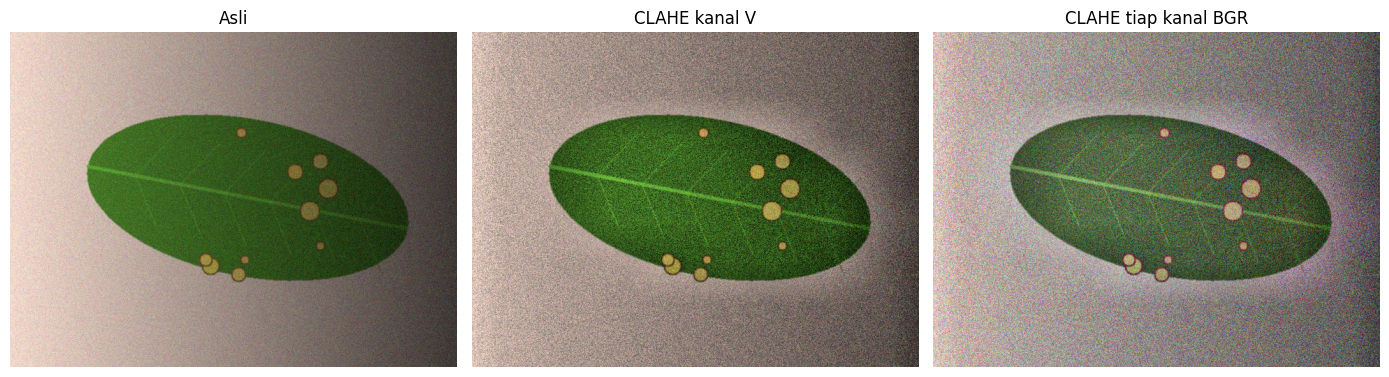

In [6]:
# eksperimen parameter CLAHE
baris = []
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c_ = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        kb = kontras_bercak(c_, md, mb)
        baris.append([clip, tile, round(kb, 2)])
        print(f"clip={clip} tile={tile}: KB={kb:.2f}")
pd.DataFrame(baris, columns=["clip", "tile", "KB"]).to_csv("../hasil/b3_clahe_param.csv", index=False)

# CLAHE pada citra warna: kanal V (benar) dan tiap kanal BGR (bandingkan)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c_) for c_ in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"])
plt.savefig("../hasil/b3_clahe_warna.png")

# bukti P3.4: pergeseran warna (kanal a, b Lab) pada area daun
def geser(x):
    a = cv2.cvtColor(x, cv2.COLOR_BGR2LAB).astype(float)[:, :, 1:]
    b = cv2.cvtColor(img, cv2.COLOR_BGR2LAB).astype(float)[:, :, 1:]
    return np.abs(a - b)[md > 0].mean()
print(f"pergeseran warna (Lab a,b) CLAHE-V  : {geser(via_v):.2f}")
print(f"pergeseran warna (Lab a,b) CLAHE-BGR: {geser(via_bgr):.2f}")

## Langkah 3.5 Satu perbaikan per kondisi, kelas berat dan ringan

In [7]:
def perbaiki(g, metode):
    rmin, rmax = np.percentile(g, (2, 98))
    return {
        "asli": lambda: g,
        "regang": lambda: np.clip((g - rmin) / (rmax - rmin) * 255, 0, 255).astype(np.uint8),
        "gamma0.5": lambda: cv2.LUT(g, gamma_lut(0.5)),
        "gamma1.8": lambda: cv2.LUT(g, gamma_lut(1.8)),
        "ekualisasi": lambda: cv2.equalizeHist(g),
        "CLAHE": lambda: cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g),
    }[metode]()

label = pd.read_csv(f"{D}/label.csv")
metode_uji = ["asli", "regang", "gamma0.5", "gamma1.8", "ekualisasi", "CLAHE"]
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    im, m_d, m_b = muat(d.nama_file)
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    for m in metode_uji:
        baris.append([d.kelas, d.kondisi_cahaya, m, kontras_bercak(perbaiki(g, m), m_d, m_b)])
hasil35 = pd.DataFrame(baris, columns=["kelas", "kondisi", "metode", "KB"])
rata = hasil35.groupby(["kondisi", "metode"]).KB.mean().unstack().loc[["gelap", "terang", "kontras_rendah", "bayangan"], metode_uji].round(2)
print(rata)
print("\nMetode terbaik per kondisi:", rata.idxmax(axis=1).to_dict())
rata.to_csv("../hasil/b3_perbaikan_per_kondisi.csv")

metode          asli  regang  gamma0.5  gamma1.8  ekualisasi  CLAHE
kondisi                                                            
gelap           3.88    4.23      3.05      5.53        0.92   2.09
terang          2.89    3.10      2.72      3.14        1.60   1.71
kontras_rendah  2.04    2.20      1.96      2.15        2.17   1.58
bayangan        1.87    1.92      1.63      2.34        1.33   1.83

Metode terbaik per kondisi: {'gelap': 'gamma1.8', 'terang': 'gamma1.8', 'kontras_rendah': 'regang', 'bayangan': 'gamma1.8'}


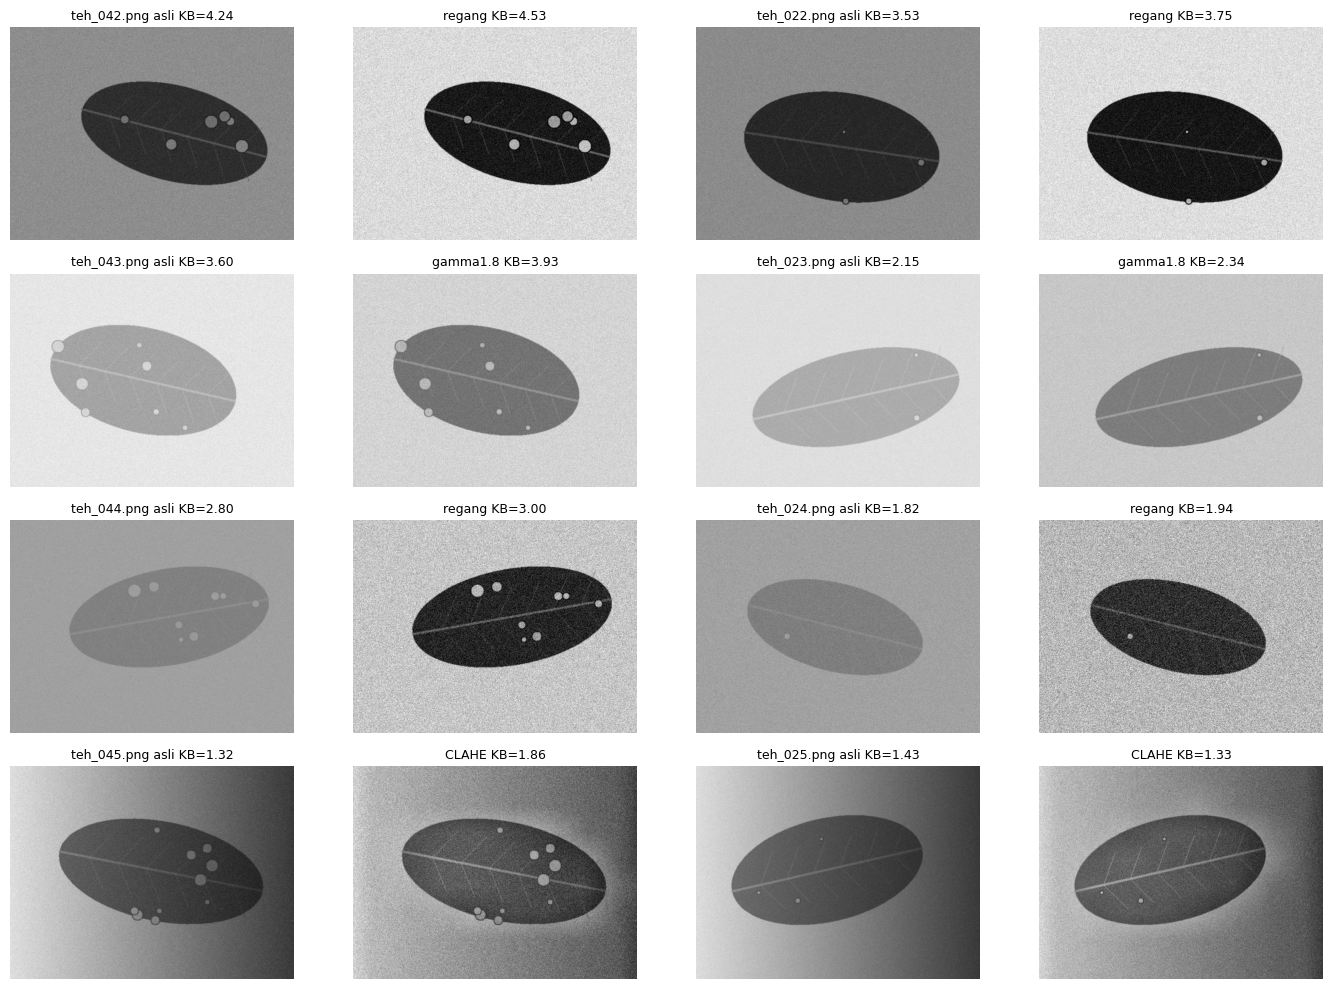

In [8]:
# panel sebelum dan sesudah: pasangan berat dan ringan untuk tiap kondisi
# pilihan akhir: KB tertinggi dipertimbangkan bersama logika histogram
# (gamma 1,8 punya KB tertinggi pada gelap dan bayangan, tetapi menggelapkan
# citra yang sudah gelap sehingga tidak dipilih)
pilihan = {"gelap": "regang", "terang": "gamma1.8",
           "kontras_rendah": "regang", "bayangan": "CLAHE"}
pasangan = {"gelap": ("teh_042.png", "teh_022.png"), "terang": ("teh_043.png", "teh_023.png"),
            "kontras_rendah": ("teh_044.png", "teh_024.png"), "bayangan": ("teh_045.png", "teh_025.png")}
fig, ax = plt.subplots(4, 4, figsize=(14, 10))
for i, (kond, (nb_, nr_)) in enumerate(pasangan.items()):
    for j, nm in enumerate([nb_, nr_]):
        im, m_d, m_b = muat(nm)
        g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
        s = perbaiki(g, pilihan[kond])
        ax[i, 2*j].imshow(g, cmap="gray", vmin=0, vmax=255); ax[i, 2*j].set_title(f"{nm} asli KB={kontras_bercak(g, m_d, m_b):.2f}", fontsize=9)
        ax[i, 2*j+1].imshow(s, cmap="gray", vmin=0, vmax=255); ax[i, 2*j+1].set_title(f"{pilihan[kond]} KB={kontras_bercak(s, m_d, m_b):.2f}", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig("../hasil/b3_sebelum_sesudah.png")

## Bukti tambahan untuk P3.3 (peregangan min-maks)

In [9]:
# satu piksel ekstrem membuat peregangan min-maks gagal
x = gray.copy().astype(float)
print("min/maks asli:", x.min(), x.max())
x2 = x.copy(); x2[0, 0] = 0; x2[0, 1] = 255        # dua piksel derau ekstrem
reg_minmax = (x2 - x2.min()) / (x2.max() - x2.min()) * 255
p2, p98 = np.percentile(x2, (2, 98))
reg_pers = np.clip((x2 - p2) / (p98 - p2) * 255, 0, 255)
print(f"setelah ada 2 piksel ekstrem: min={x2.min()}, maks={x2.max()}, persentil 2/98 = {p2:.0f}/{p98:.0f}")
print(f"simpangan baku hasil: min-maks={reg_minmax.std():.1f}, persentil={reg_pers.std():.1f}")

min/maks asli: 12.0 249.0
setelah ada 2 piksel ekstrem: min=0.0, maks=255.0, persentil 2/98 = 42/222
simpangan baku hasil: min-maks=56.7, persentil=79.8
